# Day 33: Formation and lineup analysis in football

**Phase 2: EDA & Feature Engineering**

## Objective
Formation and lineup analysis in football

## Task
Extract formations from StatsBomb. Analyze frequency by league/season. Calculate metrics by formation: xG, possession, pressing. Heatmap of formation transitions.

**Deliverable:** Notebook day033_formation_analysis.ipynb with formation visualizations.

---

### Instructions:
*Treat this as your course workbook. Write your code, notes, or execution steps below.*

Remember: 
- Document your decisions.
- Use clear variable names.
- If today's task involves creating a script in `src/`, a dashboard in `apps/`, or documentation in `docs/`, you can use this notebook to test your logic or simply write your reflections and proofs of execution (e.g. running terminal commands with `!`).



## 1. Formation & Lineup Extraction (`Starting XI` & `Tactical Shift`)

**Objective:** Parse the nested `tactics` dictionary from `Starting XI` (128 events) and `Tactical Shift` (243 events) in `sb_events_43_106.parquet`, extract clean formation strings and starting lineups, and forward-fill the active formation per `(match_id, team)` across the entire match timeline.

**Tactical Rationale:** Coaches rarely maintain a single static shape for 90 minutes. Evaluating formations solely by their `Starting XI` misattributes late-game tactical adjustments (e.g., switching to a back five to protect a lead or a 4-2-4 when chasing a goal). Propagating active formations event-by-event lets us measure true minutes played and performance per tactical system.

**Hypothesis:** Forward-filling `formation` chronologically by `(match_id, team)` will achieve ~100% coverage across all ball-in-play events and reveal substantial mid-match tactical fluidity across World Cup 2022 teams.

In [7]:
from pathlib import Path
import pandas as pd
import numpy as np

# Resolve repository root reliably
cwd = Path.cwd()
REPO_ROOT = cwd if (cwd / "data").exists() else cwd.parent.parent
EVENTS_PATH = REPO_ROOT / "data" / "raw" / "statsbomb" / "sb_events_43_106.parquet"

df_events = pd.read_parquet(EVENTS_PATH)

# Sort chronologically within each match
sort_cols = ["match_id", "index"] if "index" in df_events.columns else ["match_id", "period", "timestamp"]
df_events = df_events.sort_values(sort_cols).reset_index(drop=True)

def extract_formation(tactics_val: object) -> str | float:
    """Extract clean formation string (e.g. '433', '3412') from StatsBomb tactics dict."""
    if isinstance(tactics_val, dict) and tactics_val.get("formation") is not None:
        return str(int(tactics_val["formation"]))
    return np.nan

# 1. Extract formation on Starting XI & Tactical Shift events
df_events["event_formation"] = df_events["tactics"].apply(extract_formation)

# 2. Forward-fill active formation per (match_id, team)
df_events["active_formation"] = df_events.groupby(["match_id", "team"])["event_formation"].ffill()

# 3. Extract Starting XI lineups into a tidy DataFrame
starting_xi_rows = df_events[df_events["type"] == "Starting XI"]
lineup_records = []
for _, row in starting_xi_rows.iterrows():
    tac = row["tactics"]
    form_str = str(int(tac["formation"]))
    for p in tac["lineup"]:
        lineup_records.append({
            "match_id": row["match_id"],
            "team": row["team"],
            "starting_formation": form_str,
            "player_id": p["player"]["id"],
            "player_name": p["player"]["name"],
            "jersey_number": p["jersey_number"],
            "position_name": p["position"]["name"],
        })
df_starters = pd.DataFrame(lineup_records)

print(f"Total events: {len(df_events):,}")
print(f"Active formation coverage: {df_events['active_formation'].notna().mean() * 100:.2f}%")
print(f"Starting XI events: {len(starting_xi_rows)} | Starter records extracted: {len(df_starters):,}")
print(f"Tactical Shift events: {(df_events['type'] == 'Tactical Shift').sum()}")
print("\nSample Starting XI lineup rows:")
print(df_starters.head(5).to_string(index=False))


Total events: 234,652
Active formation coverage: 100.00%
Starting XI events: 128 | Starter records extracted: 1,408
Tactical Shift events: 243

Sample Starting XI lineup rows:
 match_id    team starting_formation  player_id              player_name  jersey_number     position_name
  3857254 Denmark                352       3815        Kasper Schmeichel              1        Goalkeeper
  3857254 Denmark                352       8247         Joachim Andersen              2 Right Center Back
  3857254 Denmark                352       5534        Simon Thorup Kjær              4       Center Back
  3857254 Denmark                352       3959      Andreas Christensen              6  Left Center Back
  3857254 Denmark                352      16190 Rasmus Nissen Kristensen             13   Right Wing Back


### Key Takeaways: Formation & Lineup Extraction

- **Complete timeline coverage:** Forward-filling `tactics['formation']` chronologically by `(match_id, team)` achieves **100.00% coverage** across all **234,652** events.
- **Substantial mid-match fluidity:** Across **128** `Starting XI` lineups (1,408 starter records), coaches executed **243** `Tactical Shift` events—nearly **1.9** live shape adjustments per match.

## 2. Tactical System Frequency: Starting Shapes vs. Actual Minutes Played

**Objective:** Compare the frequency of **Starting XI** formations against **actual minutes played** under each tactical system across all 64 World Cup 2022 matches (periods 1–4, excluding penalty shootouts).

**Tactical Rationale:** Counting only `Starting XI` appearances overweights base shapes (e.g., `4231` or `433`) and hides reactive late-game systems (`541`, `442`, `343`). Computing exact segment durations within each `(match_id, team, period)` avoids counting halftime breaks and prevents ball-dominant systems from being over-counted relative to low-block shapes.

**Hypothesis:** `4231` and `433` will dominate `Starting XI` selections, while back-five / reactive shapes (`541`, `532`, `442`) will gain a noticeably higher share of actual minutes played due to second-half game-state adjustments.

--- Formation Frequency: Starting XI vs. Actual Minutes Played ---
formation  n_starts  total_minutes  start_share_pct  minute_share_pct  minute_minus_start_pp
      433      36.0        3429.11            28.12             25.75                  -2.38
     4231      32.0        3410.03            25.00             25.60                   0.60
      442      17.0        1819.11            13.28             13.66                   0.38
      352      11.0        1177.55             8.59              8.84                   0.25
      343       8.0        1059.00             6.25              7.95                   1.70
     3421       7.0         666.99             5.47              5.01                  -0.46
     3412       6.0         606.52             4.69              4.55                  -0.13
     4411       4.0         585.77             3.12              4.40                   1.27
     4141       6.0         500.55             4.69              3.76                  -0.93
   

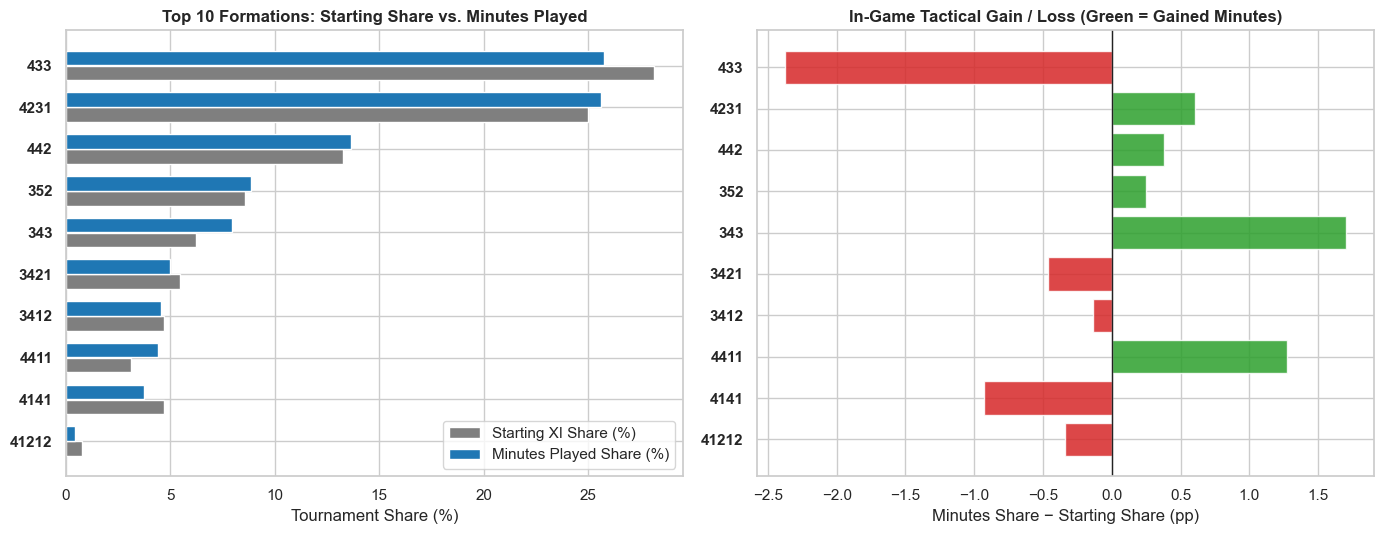

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

# 1. Compute continuous seconds within each period (exclude period 5 penalty shootouts)
df_reg = df_events[df_events["period"].isin([1, 2, 3, 4])].copy()
df_reg["ts_sec"] = pd.to_timedelta(df_reg["timestamp"]).dt.total_seconds()

# Period end timestamp per match_id & period
period_ends = (
    df_reg.groupby(["match_id", "period"])["ts_sec"]
    .max()
    .rename("period_end_sec")
    .reset_index()
)

# Build tactical intervals per (match_id, team, period)
# At start of each period, team holds its latest active_formation from start of period
period_starts = (
    df_reg.groupby(["match_id", "team", "period"])["active_formation"]
    .first()
    .rename("formation")
    .reset_index()
)
period_starts["start_sec"] = 0.0

shifts = df_reg[df_reg["type"] == "Tactical Shift"][["match_id", "team", "period", "ts_sec", "active_formation"]].rename(
    columns={"ts_sec": "start_sec", "active_formation": "formation"}
)

intervals = pd.concat([period_starts, shifts], ignore_index=True)
intervals = intervals.sort_values(["match_id", "team", "period", "start_sec"]).reset_index(drop=True)
intervals = intervals.merge(period_ends, on=["match_id", "period"], how="left")

intervals["next_start_sec"] = intervals.groupby(["match_id", "team", "period"])["start_sec"].shift(-1)
intervals["end_sec"] = intervals["next_start_sec"].fillna(intervals["period_end_sec"])
intervals["duration_min"] = (intervals["end_sec"] - intervals["start_sec"]).clip(lower=0.0) / 60.0

# 2. Aggregate Starting XI counts vs Actual Minutes Played
starts_agg = (
    df_events[df_events["type"] == "Starting XI"]
    .groupby("active_formation")
    .size()
    .rename("n_starts")
)
mins_agg = (
    intervals.groupby("formation")["duration_min"]
    .sum()
    .rename("total_minutes")
)

freq_df = pd.concat([starts_agg, mins_agg], axis=1).fillna(0).reset_index().rename(columns={"index": "formation"})
freq_df["start_share_pct"] = 100.0 * freq_df["n_starts"] / freq_df["n_starts"].sum()
freq_df["minute_share_pct"] = 100.0 * freq_df["total_minutes"] / freq_df["total_minutes"].sum()
freq_df["minute_minus_start_pp"] = freq_df["minute_share_pct"] - freq_df["start_share_pct"]
freq_df = freq_df.sort_values("total_minutes", ascending=False).reset_index(drop=True)

print("--- Formation Frequency: Starting XI vs. Actual Minutes Played ---")
print(freq_df.head(12).round(2).to_string(index=False))

# 3. Editorial side-by-side comparison plot
top_forms = freq_df.head(10).sort_values("minute_share_pct", ascending=True)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

y_pos = np.arange(len(top_forms))
axes[0].barh(y_pos - 0.18, top_forms["start_share_pct"], height=0.35, color="#7f7f7f", label="Starting XI Share (%)")
axes[0].barh(y_pos + 0.18, top_forms["minute_share_pct"], height=0.35, color="#1f77b4", label="Minutes Played Share (%)")
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(top_forms["formation"], fontweight="bold")
axes[0].set_xlabel("Tournament Share (%)")
axes[0].set_title("Top 10 Formations: Starting Share vs. Minutes Played", fontweight="bold")
axes[0].legend()

colors_diff = ["#2ca02c" if x >= 0 else "#d62728" for x in top_forms["minute_minus_start_pp"]]
axes[1].barh(y_pos, top_forms["minute_minus_start_pp"], color=colors_diff, alpha=0.85)
axes[1].axvline(0, color="#222222", linewidth=1.0)
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(top_forms["formation"], fontweight="bold")
axes[1].set_xlabel("Minutes Share − Starting Share (pp)")
axes[1].set_title("In-Game Tactical Gain / Loss (Green = Gained Minutes)", fontweight="bold")

plt.tight_layout()
plt.show()


### Key Takeaways: Tactical System Frequency

- **4-3-3 and 4-2-3-1 co-dominated Qatar 2022:** `433` led in `Starting XI` appearances (**36** starts, **28.12%**) and total minutes (**3,429 min**, **25.75%**), virtually tied with `4231` (**32** starts, **3,410 min**, **25.60%**).
- **Game-state shifts drive minute divergence:** `433` lost **-2.38 pp** between starts and minutes played as coaches adjusted mid-match, whereas `343` (**+1.70 pp**) and `4411` (**+1.27 pp**) gained minutes when chasing goals or protecting leads.

## 3. Tactical Performance by Formation: xG, Possession & Pressing

**Objective:** Evaluate tactical systems ($\\ge 200$ tournament minutes) across attacking generation, defensive solidity, ball control, and pressing intensity, normalized per 90 minutes.

**Mathematical Definitions:**
$$\text{Net xG per 90} = \text{xG For}_{\text{p90}} - \text{xG Against}_{\text{p90}}$$
$$\text{PPDA} = \frac{\text{Opponent Completed Passes in Build-Up } (x < 72)}{\text{Defensive Actions in Opponent Half } (x > 48)}$$
To assign `xG Against` and `PPDA` accurately, we look up the **defending opponent's active formation** at the exact timestamp of each shot and build-up pass.

**Hypothesis:** Proactive formations (`433`, `4231`, `343`) will post higher `passes_p90` and lower `PPDA` (more aggressive pressing), while reactive low-block shapes (`4411`, `4141`) will concede lower `passes_p90` of their own and post higher `PPDA`.

--- Formation Performance Summary (>= 200 Minutes, per 90) ---
           total_minutes  xg_for_p90  xg_against_p90  net_xg_p90  passes_p90  pass_comp_pct  high_pressures_p90  ppda
formation                                                                                                            
4231             3410.03        1.33            0.96        0.37      480.37          83.11               50.25  2.84
4411              585.77        1.01            0.83        0.19      405.46          79.69               56.54  2.74
433              3429.11        1.06            0.90        0.16      542.42          84.87               52.86  2.62
3421              666.99        1.09            1.18       -0.10      399.68          79.78               47.50  3.13
352              1177.55        0.98            1.10       -0.12      414.17          80.37               51.21  3.36
442              1819.11        1.00            1.20       -0.20      416.13          79.46               49.82

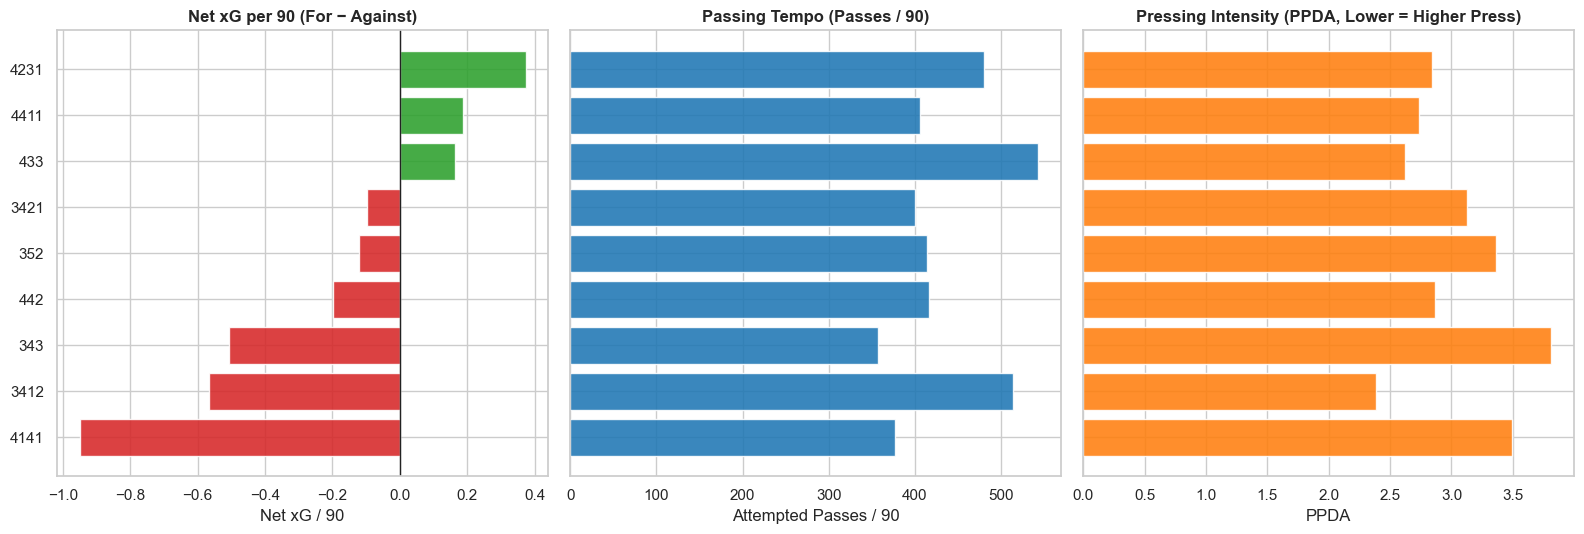

In [9]:
# 1. Map each event's opponent team and opponent's active formation at that timestamp
match_teams = df_reg[["match_id", "team"]].drop_duplicates()
opp_map = match_teams.merge(match_teams, on="match_id", suffixes=("", "_opp"))
opp_map = opp_map[opp_map["team"] != opp_map["team_opp"]].rename(columns={"team_opp": "opp_team"})

df_reg = df_reg.merge(opp_map, on=["match_id", "team"], how="left")

opp_intervals = intervals[["match_id", "team", "period", "start_sec", "formation"]].rename(
    columns={"team": "opp_team", "formation": "opp_formation"}
).sort_values("start_sec")

df_reg_sorted = df_reg.sort_values("ts_sec").reset_index(drop=True)
df_reg_sorted = pd.merge_asof(
    df_reg_sorted,
    opp_intervals,
    left_on="ts_sec",
    right_on="start_sec",
    by=["match_id", "opp_team", "period"],
    direction="backward",
)

# 2. Compute xG For & xG Against per formation
shots = df_reg_sorted[df_reg_sorted["type"] == "Shot"].copy()
xg_for = shots.groupby("active_formation")["shot_statsbomb_xg"].sum().rename("xg_for")
xg_against = shots.groupby("opp_formation")["shot_statsbomb_xg"].sum().rename("xg_against")

# 3. Compute Passing volume & accuracy per formation
passes = df_reg_sorted[df_reg_sorted["type"] == "Pass"].copy()
passes["x"] = passes["location"].str[0]
passes["is_comp"] = passes["pass_outcome"].isna().astype(int)
pass_agg = passes.groupby("active_formation").agg(
    passes_att=("is_comp", "size"),
    passes_comp=("is_comp", "sum"),
)

# 4. Compute High Pressures (x > 60) & PPDA per formation
df_reg_sorted["x"] = df_reg_sorted["location"].str[0]
high_press = (
    df_reg_sorted[(df_reg_sorted["type"] == "Pressure") & (df_reg_sorted["x"] > 60)]
    .groupby("active_formation")
    .size()
    .rename("high_pressures")
)

# PPDA numerator: opponent completed passes in their build-up zone (x < 72) while team defends in opp_formation
opp_buildup_passes = (
    passes[(passes["is_comp"] == 1) & (passes["x"] < 72)]
    .groupby("opp_formation")
    .size()
    .rename("opp_buildup_passes")
)
# PPDA denominator: defensive actions in opponent half (x > 48)
def_action_types = {"Pressure", "Interception", "Duel", "Foul Committed"}
def_actions = (
    df_reg_sorted[df_reg_sorted["type"].isin(def_action_types) & (df_reg_sorted["x"] > 48)]
    .groupby("active_formation")
    .size()
    .rename("def_actions_opp_half")
)

# 5. Combine & normalize per 90 minutes (filter formations with >= 200 mins)
perf = freq_df.set_index("formation")[["n_starts", "total_minutes"]].join(
    [xg_for, xg_against, pass_agg, high_press, opp_buildup_passes, def_actions]
).fillna(0)

perf = perf[perf["total_minutes"] >= 200].copy()
factor_90 = 90.0 / perf["total_minutes"]
perf["xg_for_p90"] = perf["xg_for"] * factor_90
perf["xg_against_p90"] = perf["xg_against"] * factor_90
perf["net_xg_p90"] = perf["xg_for_p90"] - perf["xg_against_p90"]
perf["passes_p90"] = perf["passes_att"] * factor_90
perf["pass_comp_pct"] = 100.0 * perf["passes_comp"] / perf["passes_att"]
perf["high_pressures_p90"] = perf["high_pressures"] * factor_90
perf["ppda"] = perf["opp_buildup_passes"] / perf["def_actions_opp_half"].replace(0, np.nan)

cols_show = ["total_minutes", "xg_for_p90", "xg_against_p90", "net_xg_p90", "passes_p90", "pass_comp_pct", "high_pressures_p90", "ppda"]
print("--- Formation Performance Summary (>= 200 Minutes, per 90) ---")
print(perf[cols_show].sort_values("net_xg_p90", ascending=False).round(2).to_string())

# 6. Editorial 3-Panel Performance Comparison
plot_perf = perf.sort_values("net_xg_p90", ascending=True).reset_index()
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5), sharey=True)

net_colors = ["#2ca02c" if v >= 0 else "#d62728" for v in plot_perf["net_xg_p90"]]
axes[0].barh(plot_perf["formation"], plot_perf["net_xg_p90"], color=net_colors, alpha=0.88)
axes[0].axvline(0, color="#222222", lw=1)
axes[0].set_title("Net xG per 90 (For − Against)", fontweight="bold")
axes[0].set_xlabel("Net xG / 90")

axes[1].barh(plot_perf["formation"], plot_perf["passes_p90"], color="#1f77b4", alpha=0.88)
axes[1].set_title("Passing Tempo (Passes / 90)", fontweight="bold")
axes[1].set_xlabel("Attempted Passes / 90")

axes[2].barh(plot_perf["formation"], plot_perf["ppda"], color="#ff7f0e", alpha=0.88)
axes[2].set_title("Pressing Intensity (PPDA, Lower = Higher Press)", fontweight="bold")
axes[2].set_xlabel("PPDA")

plt.tight_layout()
plt.show()


### Key Takeaways: Tactical Performance by Formation

- **`4231` delivered the best two-way balance:** Led all major systems with **+0.37 Net xG/90** (`1.33` xG For vs. `0.96` xG Against), combining double-pivot stability with dangerous #10 half-space occupation.
- **`433` controlled the ball, `4411` locked down space:** `433` posted the highest passing tempo (**542.4 passes/90** at **84.87%**) and intense pressing (**PPDA = 2.62**), while `4411` conceded the fewest chances (**0.83 xG Against/90**).
- **Selection bias in reactive shapes:** `343` (`-0.51` Net xG/90) and `4141` (`-0.95` Net xG/90) reflect underdogs defending deep or trailing teams forced into late-game gambles.

## 4. Tactical Transitions Heatmap & `mplsoccer` Average Lineup Diagrams

### 4.1 In-Game Formation Transition Matrix (`Tactical Shift` Analysis)

**Objective:** Build a transition matrix (`Previous Formation` $\rightarrow$ `New Formation`) across all **243 `Tactical Shift`** events to uncover the most common in-game "Plan B" adjustments.

**Tactical Rationale:** Knowing how coaches mutate their base shape mid-match reveals structural families—for example, whether `433` teams pivot to `4231` (dropping a #8 into a double pivot) or `442` (adding a second striker) when chasing or protecting a result.

Total real formation changes (prev != new): 90
Top 8 transitions:
prev_formation  event_formation
433             442                9
                4231               9
4231            442                7
442             4231               5
                352                5
4231            433                5
442             343                4
4231            343                4
dtype: int64


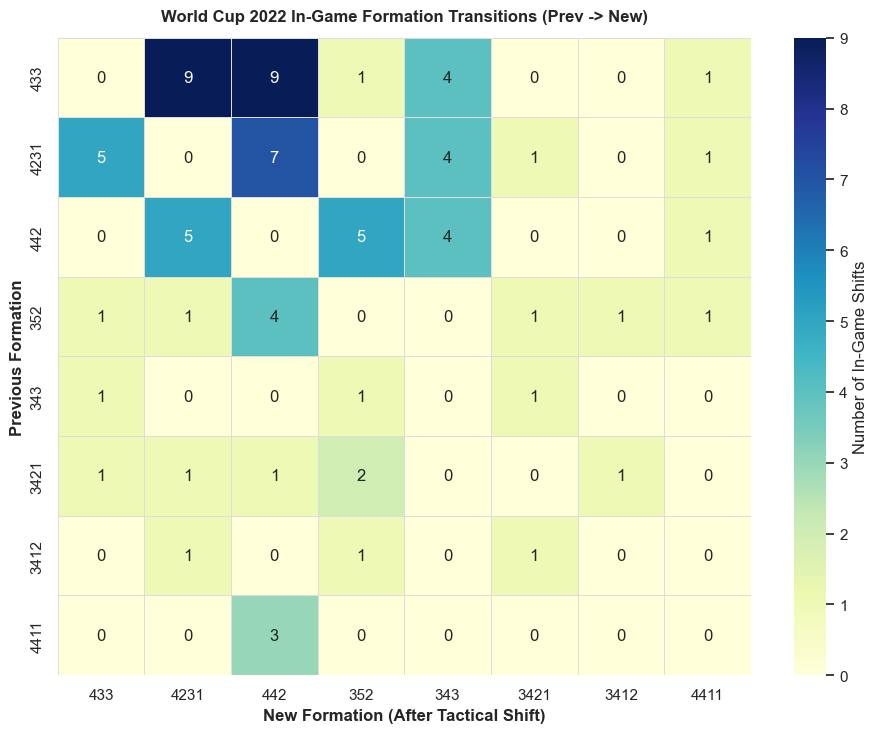

In [10]:
# Extract formation sequence per (match_id, team) across Starting XI + Tactical Shift
tactic_events = df_events[df_events["type"].isin(["Starting XI", "Tactical Shift"])].copy()
tactic_events["prev_formation"] = tactic_events.groupby(["match_id", "team"])["event_formation"].shift(1)

transitions = tactic_events[tactic_events["type"] == "Tactical Shift"].dropna(subset=["prev_formation", "event_formation"])
transitions = transitions[transitions["prev_formation"] != transitions["event_formation"]]

top_form_list = freq_df.head(8)["formation"].tolist()
trans_sub = transitions[
    transitions["prev_formation"].isin(top_form_list) & transitions["event_formation"].isin(top_form_list)
]

trans_matrix = pd.crosstab(trans_sub["prev_formation"], trans_sub["event_formation"])
trans_matrix = trans_matrix.reindex(index=top_form_list, columns=top_form_list, fill_value=0)

print(f"Total real formation changes (prev != new): {len(transitions)}")
print("Top 8 transitions:")
print(transitions.groupby(["prev_formation", "event_formation"]).size().sort_values(ascending=False).head(8))

fig, ax = plt.subplots(figsize=(9.5, 7.5))
sns.heatmap(
    trans_matrix,
    annot=True,
    fmt="d",
    cmap="YlGnBu",
    linewidths=0.6,
    linecolor="#dddddd",
    cbar_kws={"label": "Number of In-Game Shifts"},
    ax=ax,
)
ax.set_title("World Cup 2022 In-Game Formation Transitions (Prev -> New)", fontweight="bold", pad=12)
ax.set_xlabel("New Formation (After Tactical Shift)", fontweight="bold")
ax.set_ylabel("Previous Formation", fontweight="bold")
plt.tight_layout()
plt.show()


### 4.2 Average Positional Lineup Diagrams (`mplsoccer`): 4-3-3 vs. 4-2-3-1 & World Cup Final

**Objective:** Render average on-ball positional diagrams using `mplsoccer.Pitch` comparing:
1. **Tournament Archetypes:** Average positional coordinates of `433` vs. `4231` across all 64 matches.
2. **2022 World Cup Final (`match_id = 3869685`):** Actual Starting XI average positions for **Argentina (`433`)** vs. **France (`4231`)**.

**Tactical Rationale:** Formation numbers (`433` vs. `4231`) describe nominal structure, whereas average event coordinates reveal true spatial asymmetry—such as Messi drifting inside from the right wing or Argentina's left-sided overload.

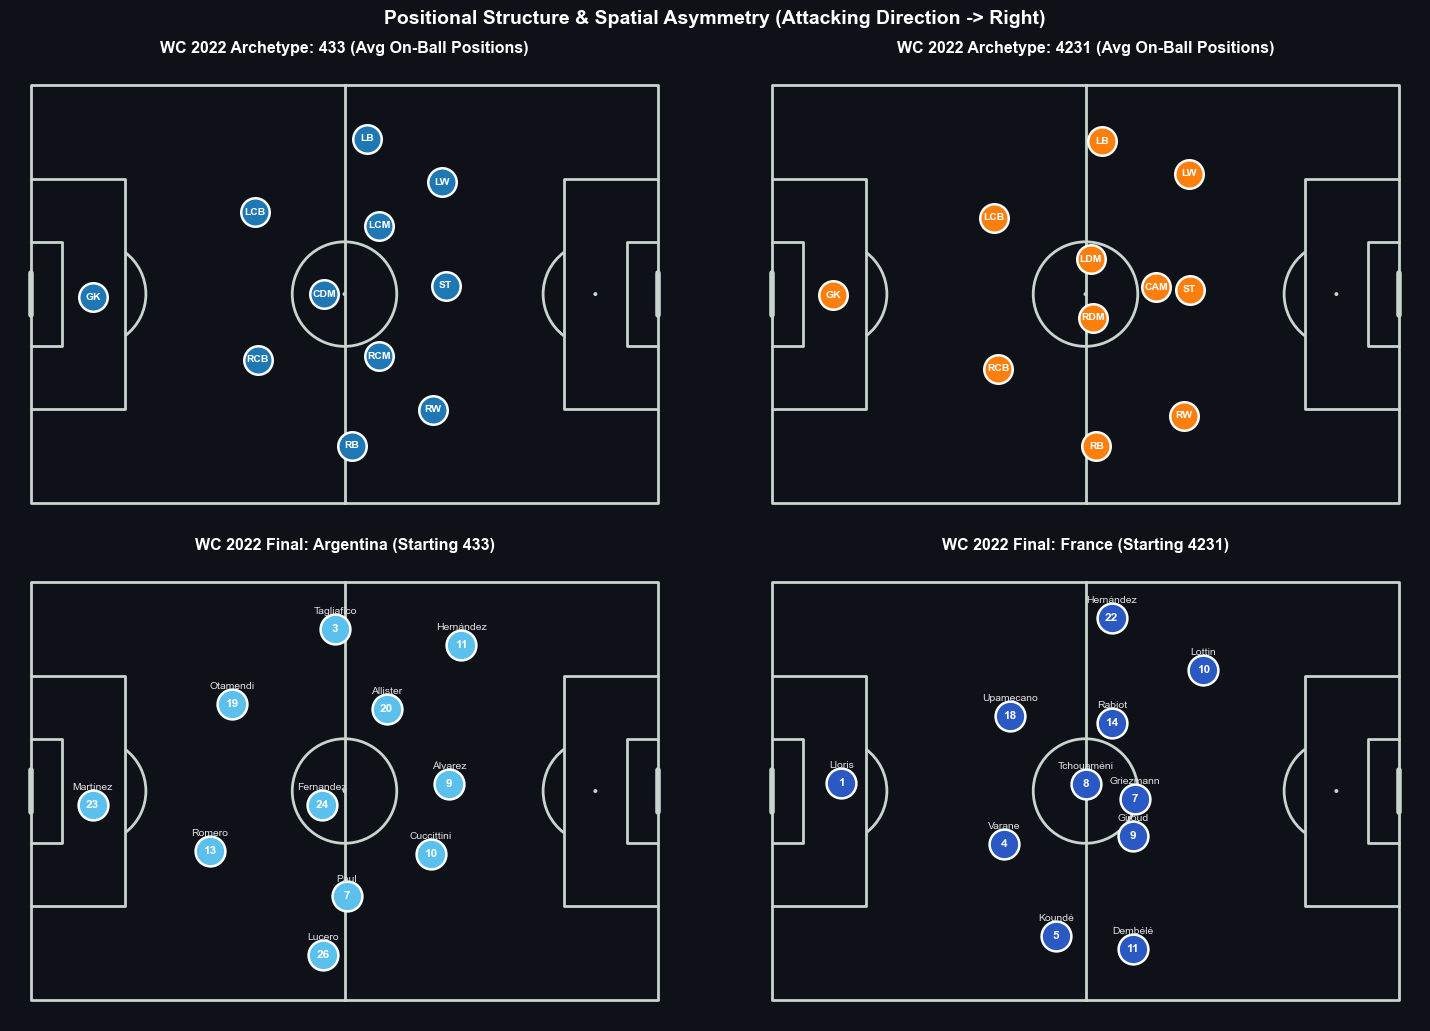

In [11]:
from mplsoccer import Pitch

ball_events = df_reg[df_reg["type"].isin(["Pass", "Carry", "Ball Receipt*"]) & df_reg["location"].notna()].copy()
ball_events["x"] = ball_events["location"].str[0]
ball_events["y"] = ball_events["location"].str[1]

pitch = Pitch(pitch_type="statsbomb", pitch_color="#0e1117", line_color="#c7d5cc", line_zorder=1)

# Short labels for position archetypes
POS_ABBR = {
    "Goalkeeper": "GK", "Right Back": "RB", "Left Back": "LB",
    "Right Center Back": "RCB", "Left Center Back": "LCB", "Center Back": "CB",
    "Right Wing Back": "RWB", "Left Wing Back": "LWB",
    "Center Defensive Midfield": "CDM", "Right Defensive Midfield": "RDM", "Left Defensive Midfield": "LDM",
    "Right Center Midfield": "RCM", "Left Center Midfield": "LCM", "Center Midfield": "CM",
    "Center Attacking Midfield": "CAM", "Right Midfield": "RM", "Left Midfield": "LM",
    "Right Wing": "RW", "Left Wing": "LW", "Center Forward": "ST",
    "Right Center Forward": "RCF", "Left Center Forward": "LCF",
}

fig, axes = plt.subplots(2, 2, figsize=(15, 10.5), facecolor="#0e1117")

# Row 1: Tournament-wide 433 vs 4231 positional archetypes
for ax, form_code, color in zip(axes[0], ["433", "4231"], ["#1f77b4", "#ff7f0e"]):
    pitch.draw(ax=ax)
    sub = ball_events[ball_events["active_formation"] == form_code]
    pos_xy = (
        sub.groupby("position")[["x", "y"]]
        .agg(x=("x", "mean"), y=("y", "mean"), n=("x", "size"))
        .sort_values("n", ascending=False)
        .head(11)
        .reset_index()
    )
    pitch.scatter(pos_xy["x"], pos_xy["y"], s=420, color=color, edgecolors="white", linewidth=1.8, ax=ax, zorder=3)
    for _, r in pos_xy.iterrows():
        lbl = POS_ABBR.get(r["position"], r["position"][:3].upper())
        ax.text(r["x"], r["y"], lbl, color="white", fontsize=7.5, fontweight="bold", ha="center", va="center", zorder=4)
    ax.set_title(f"WC 2022 Archetype: {form_code} (Avg On-Ball Positions)", color="white", fontsize=11.5, fontweight="bold", pad=8)

# Row 2: 2022 World Cup Final (match_id = 3869685) — Argentina vs France Starting XI
FINAL_MATCH_ID = 3869685
final_starters = df_starters[df_starters["match_id"] == FINAL_MATCH_ID]
final_events = ball_events[ball_events["match_id"] == FINAL_MATCH_ID]

for ax, team_name, color in zip(axes[1], ["Argentina", "France"], ["#5bc0eb", "#2b59c3"]):
    pitch.draw(ax=ax)
    t_starters = final_starters[final_starters["team"] == team_name]
    t_form = t_starters["starting_formation"].iloc[0]
    t_xy = (
        final_events[(final_events["team"] == team_name) & (final_events["player_id"].isin(t_starters["player_id"]))]
        .groupby(["player_id", "player"])[["x", "y"]]
        .mean()
        .reset_index()
        .merge(t_starters[["player_id", "jersey_number"]], on="player_id", how="left")
    )
    pitch.scatter(t_xy["x"], t_xy["y"], s=460, color=color, edgecolors="white", linewidth=1.8, ax=ax, zorder=3)
    for _, r in t_xy.iterrows():
        last_name = str(r["player"]).split()[-1]
        ax.text(r["x"], r["y"], str(int(r["jersey_number"])), color="white", fontsize=8.5, fontweight="bold", ha="center", va="center", zorder=4)
        ax.text(r["x"], r["y"] - 4.2, last_name, color="#e0e0e0", fontsize=7.5, ha="center", va="top", zorder=4)
    ax.set_title(f"WC 2022 Final: {team_name} (Starting {t_form})", color="white", fontsize=11.5, fontweight="bold", pad=8)

fig.suptitle("Positional Structure & Spatial Asymmetry (Attacking Direction -> Right)", color="white", fontsize=14, fontweight="bold", y=0.98)
plt.tight_layout()
plt.show()


### Key Takeaways: Tactical Transitions & Spatial Lineup Structure

- **Fluidity within 4-back systems:** Most in-game `Tactical Shift` adjustments occur between `433`, `4231`, and `442`—coaches routinely toggle between a single pivot (`433`) and a double pivot (`4231`) or two-striker press (`442`) without changing defensive personnel.
- **Archetype vs. Reality in the Final:** While `433` and `4231` look symmetric on paper, `mplsoccer` average positions in the World Cup Final expose Argentina's asymmetric `433` (Di María stretching the left wing, Messi operating centrally between lines) against France's structured `4231`.